### Coding Attention mechanisms

#### Problem with modeling long sequences
- In the pre-LLM era, encoder-decoder architecture with RNNs were the popular ones. The encoder takes the sequence of text tokens, process them sequentially and output a final hiddent state encapsulating relevant informationn
- This will be passed on to the decoder for generating next word. Decoder can have access to the final hidden states of the encoder.
- This process cannot be parallelized, needs to be processed sequentially.
- Information loss can occur for long context text inputs.
- Later attention mechanisms (Bahdanau) were introduced 2014 in the same architecture which would allow decoder to access the hidden states at each time step of the encoder. This helps the decoder to understand which tokens need more attention while generating text. This means some tokens are more important than others while generating text.
- In 2017, transformers wheere introduced with self attention inspired by the Bahdanau attention.
- At each decoding step, attention weights were needed to calculate for each of the hidden states of encoder which is computationally expensive.
- Attentions is basically how relevant/important are different words while prediction.

#### Self attention:
- "Self" attention focus on how each token is related to rest of the tokens in an input text. It assess and learn relationships and dependencies between various parts of the input text and compute the attention weights. Previous attention mechanism focussed on how decoder state is related to encoder state.
- This means, for an input token, I will know which are the other important words related to the input token.
- This allow each token in sequence to interact with and weigh the importance of other token positions in the sequence.

#### Simple self-attention withoug trainable weights
- Basically take the dot product of a vector with rest of the rest of vectors and normalize with softmax to obtain the attention scores in the simplest manner.
- Dot product measuring similiary determines the extent to which each element in sequence "focuses on" or "attends to" any other element.    

In [1]:
# Import the libraries
import re
import urllib.request
from importlib.metadata import version
import tiktoken
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

In [2]:
# the text:  Your journey starts here and assume below are the embedding of each word
inputs = torch.tensor(
  [[0.43, 0.15, 0.89], # Your     (x^1)
   [0.55, 0.87, 0.66], # journey  (x^2)
   [0.57, 0.85, 0.64], # starts   (x^3)
   [0.22, 0.58, 0.33], # with     (x^4)
   [0.77, 0.25, 0.10], # one      (x^5)
   [0.05, 0.80, 0.55]] # step     (x^6)
)

attn_scores = torch.empty(6, 6)
for i, x_i in enumerate(inputs):
    for j, x_j in enumerate(inputs):
        attn_scores[i, j] = torch.dot(x_i, x_j)
print(attn_scores)  

tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310],
        [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865],
        [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605],
        [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]])


In [3]:
# Same attention scores can be calculated by just an outer product
attn_scores = inputs @ inputs.T
print(attn_scores)

tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310],
        [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865],
        [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605],
        [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]])


In [4]:
attn_weights = torch.softmax(attn_scores, dim=-1)
print(attn_weights)

tensor([[0.2098, 0.2006, 0.1981, 0.1242, 0.1220, 0.1452],
        [0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581],
        [0.1390, 0.2369, 0.2326, 0.1242, 0.1108, 0.1565],
        [0.1435, 0.2074, 0.2046, 0.1462, 0.1263, 0.1720],
        [0.1526, 0.1958, 0.1975, 0.1367, 0.1879, 0.1295],
        [0.1385, 0.2184, 0.2128, 0.1420, 0.0988, 0.1896]])


- Context vector is obtained by multiplying the attention weights corresponding to each token and adding them together
 or basically they are weighted addition of input tokens
- This will be a simple matrix multiplication between attention weight and the input matrix
- Attention weights determine the extent to which context vector depends on different parts of the input

In [5]:

all_context_vecs = attn_weights @ inputs
print(all_context_vecs)  

tensor([[0.4421, 0.5931, 0.5790],
        [0.4419, 0.6515, 0.5683],
        [0.4431, 0.6496, 0.5671],
        [0.4304, 0.6298, 0.5510],
        [0.4671, 0.5910, 0.5266],
        [0.4177, 0.6503, 0.5645]])


#### Self attention with trainable weights
- Self attention mechanism also called scaled dot-product attentions
- Here we introduce 3 trainable weight matrices Wq, Wk, Wv which stands for query, key and value.
- The three matrices are used to create query, key and value vectors.
- Query and key vectors are dotted to get the attention weight. This attention weight is multiplied with the value vector to get the context information.
- Key, query, value are derived from the context of databases, used to store, search and retrieve information.
- Query is analogous to search query in a database. Here in LLMs, we are asking about a certain aspect/element about the tokens.
- Key is used for indexing and searching. Now, do we have information corresponding to our query?
- Value refers to actual key-value pair. If key exist, what the information corresponding to the key.
- For a sentence like "Sara went to dinner with her Friend at Wendys". Queries could be : Who went to restaurant? When did she go? Where did she go?  Keys represent if such information exist. Values retrieve the information if the keys corresponding to the query exists.
- Rationale behind scaled dot product attention: Attention scores are normalized by the size of the embedding dimension. This is used to improve the training performance by avoiding small gradients.
- Usually key, query values are random variable with 0 mean and 1 variance. A dot product in d dimentions will scale the variance to 'd' . For large embedding this dot product will be large values and cause problems with softmax function.
- Softmax acts like a smooth distribution when the inputs are closer. In the other case, the winning token get 100% probability and rest would be zero. This would kill the learning signals of the other tokens. Basically attention weight would be dominated by one token. The resulting gradient associated with the softmax function: p*(1-p) ~ 0. This will slow down learning and stagnate the training process.
- The derivative (gradient) of the softmax function for an output probability p is calculated as p × (1 - p).
    1. At a score Gap of 0 between inputs (p = 0.5): The gradient is (0.5*(1 - 0.5) = 0.25). This is the mathematical maximum. The network is wide awake and making major adjustments based on its errors.
    2. At a Gap of 12 (p ≈ 0.999994): The gradient is 0.999994 * (1 - 0.999994) = 0.000006). Because deep neural networks rely on multiplying gradients across layers during backpropagation, multiplying by a number this small completely zeros out the updates.

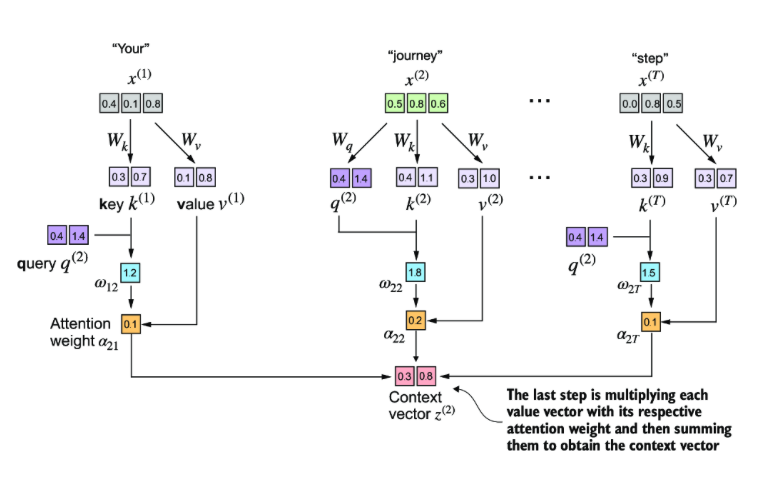

In [13]:
# Let's try to create the context vector for the second input token:
x_2 = inputs[1]     #1
d_in = inputs.shape[1]      #2
d_out = 3  # output size of the context vector

In [18]:
# Initialize 3 matrices, Wq, Wk and Wv
torch.manual_seed(123)
W_query = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_key   = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_value = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)

query_2 = x_2 @ W_query 
key_2 = x_2 @ W_key 
value_2 = x_2 @ W_value
print(query_2)

tensor([0.8520, 0.4161, 1.0138])


In [19]:
# All key and values can also be obtained 
keys = inputs @ W_key 
values = inputs @ W_value
print("keys.shape:", keys.shape)
print("values.shape:", values.shape)

keys.shape: torch.Size([6, 3])
values.shape: torch.Size([6, 3])


In [20]:
# Gives the attention score for the second token
attn_scores_2 = query_2 @ keys.T       #1
print(attn_scores_2)

# Normalize the scores by the square root of the dimension of the embedding
d_k = keys.shape[-1]
attn_weights_2 = torch.softmax(attn_scores_2 / d_k**0.5, dim=-1)
print(attn_weights_2)

tensor([1.7872, 2.0141, 2.0091, 0.9952, 1.3538, 1.1227])
tensor([0.1862, 0.2123, 0.2117, 0.1179, 0.1450, 0.1269])


In [21]:
context_vec_2 = attn_weights_2 @ values
print(context_vec_2)  

tensor([0.6864, 1.0577, 1.1389])


In [14]:
# Let's implement them in a class

class SelfAttention_v1(nn.Module):
    def __init__(self, d_in, d_out):
        super().__init__()
        self.W_query = nn.Parameter(torch.rand(d_in, d_out))
        self.W_key   = nn.Parameter(torch.rand(d_in, d_out))
        self.W_value = nn.Parameter(torch.rand(d_in, d_out))

    def forward(self, x):
        keys = x @ self.W_key # projection of input into query, key and value vectors
        queries = x @ self.W_query
        values = x @ self.W_value
        attn_scores = queries @ keys.T # omega
        attn_weights = torch.softmax(
            attn_scores / keys.shape[-1]**0.5, dim=-1
        )
        context_vec = attn_weights @ values # basically determines the importance of each word with other words
        return context_vec

In [15]:
torch.manual_seed(123)
sa_v1 = SelfAttention_v1(d_in, d_out)
print(sa_v1(inputs))

tensor([[0.6692, 1.0276, 1.1106],
        [0.6864, 1.0577, 1.1389],
        [0.6860, 1.0570, 1.1383],
        [0.6738, 1.0361, 1.1180],
        [0.6711, 1.0307, 1.1139],
        [0.6783, 1.0441, 1.1252]], grad_fn=<MmBackward0>)


- During the training, the query, key and value matrix weights are updated so that they have all the right information.
- Basically query can ask all important questions. Key and Values have the right information extracted from the input text as well.
- Let's create a better version with linear layers, nn.linear instead of nn.parameter. nn.linear has better weights initialization or they normalize after creating tensors avoiding very small numbers while nn.parameter just uses the tensor created like torch.zeros or torch.empty >> destabilize the training.

In [23]:
class SelfAttention_v2(nn.Module):
    def __init__(self, d_in, d_out, qkv_bias=False):
        super().__init__()
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias) # bias is set to False to replicate a matrix
        self.W_key   = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)

    def forward(self, x):
        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)
        attn_scores = queries @ keys.T
        attn_weights = torch.softmax(
            attn_scores / keys.shape[-1]**0.5, dim=-1
        )
        context_vec = attn_weights @ values
        return context_vec

#### Causal Attention or Masked Attention
- For most of the decoder part of the LLMs, you want self attention mechanism to consider/focus only on the words/tokens appearing before the current token.
- Standard practice is to mask the upper diagonnal part of the attention weights. This is most important for decoders while predicting the next token.
- After masking the upper diagonnal part, we just need renormalize the weight for each row.
- Usual process can be calculate attention score >> normalize >> mask >> normalize. The second normalization ensures that there is not data leakage as the first normalization utilizes exponential of attnetions scores to be masked in the next step.
- Better approach, avoid multiple normalizations: Attention scores (unnormalized) >> mask upper diagonnal with exp(-infinity) >> Calculate attention weights (normalized)
- Addtionally, certain attention weight can be dropped out for regularization purposes. So that the model does not become overly reliant on specific set of hidden units. Drop out is only used during training and disabled later.
- Usually carried out after calculating attention weights or after applying attention weights to value vectors.

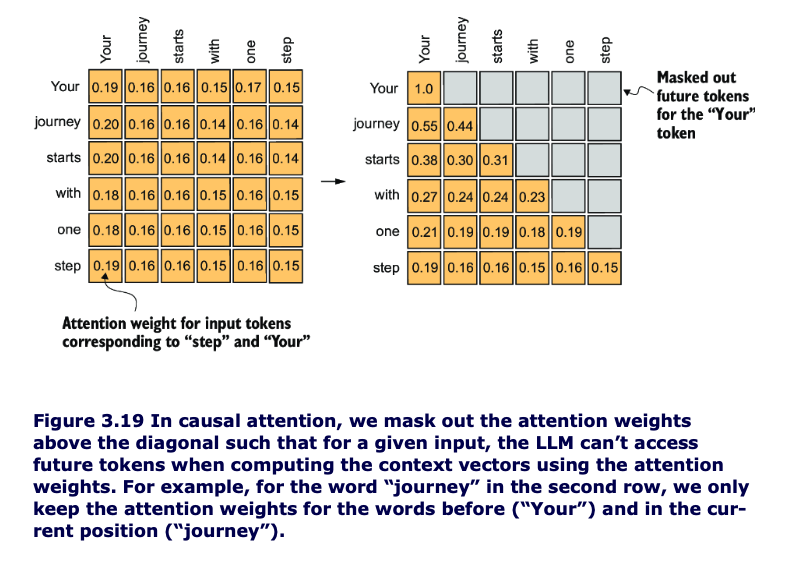

In [29]:
context_length = 6
mask = torch.triu(torch.ones(context_length, context_length), diagonal=1)
masked = attn_scores.masked_fill(mask.bool(), -torch.inf)
print(masked)

tensor([[0.9995,   -inf,   -inf,   -inf,   -inf,   -inf],
        [0.9544, 1.4950,   -inf,   -inf,   -inf,   -inf],
        [0.9422, 1.4754, 1.4570,   -inf,   -inf,   -inf],
        [0.4753, 0.8434, 0.8296, 0.4937,   -inf,   -inf],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654,   -inf],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]])


In [25]:
# In order to make up for dropping elements, rest are multipled by inverse of dropping factor
torch.manual_seed(123)
dropout = torch.nn.Dropout(0.5)    #1
example = torch.ones(6, 6)      #2
print(dropout(example))

tensor([[2., 2., 0., 2., 2., 0.],
        [0., 0., 0., 2., 0., 2.],
        [2., 2., 2., 2., 0., 2.],
        [0., 2., 2., 0., 0., 2.],
        [0., 2., 0., 2., 0., 2.],
        [0., 2., 2., 2., 2., 0.]])


In [30]:
print(dropout(masked))

tensor([[1.9990,    nan,    nan,    nan,    nan,    nan],
        [0.0000, 0.0000,   -inf,    nan,   -inf,   -inf],
        [0.0000, 2.9508, 2.9140,   -inf,   -inf,   -inf],
        [0.0000, 0.0000, 1.6592, 0.9874,    nan,   -inf],
        [0.0000, 0.0000, 0.0000, 0.0000, 1.3308,   -inf],
        [1.2620, 2.1730, 0.0000, 1.3130, 0.5870, 1.8900]])


In [26]:
## Implement causal attention which can handle batch of inputs
batch = torch.stack((inputs, inputs), dim=0)
print(batch.shape)  

torch.Size([2, 6, 3])


In [31]:
# The use of register_buffer in PyTorch is not strictly necessary for all use cases but offers several advantages here. 
# For instance, when we use the CausalAttention class in our LLM, buffers are automatically moved to the 
# appropriate device (CPU or GPU) along with our model, which will be relevant when training our LLM.

class CausalAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length,
                dropout, qkv_bias=False):
        super().__init__()
        self.d_out = d_out
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key   = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.dropout = nn.Dropout(dropout)            #1
        self.register_buffer(  # They are added here as buffers but they are not part of the weights, but part of the module.
           'mask',
           torch.triu(torch.ones(context_length, context_length),
           diagonal=1)
        )             #2

    def forward(self, x):
        b, num_tokens, d_in = x.shape                   #3
        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)

        attn_scores = queries @ keys.transpose(1, 2)   
        attn_scores.masked_fill_(                    #4
            self.mask.bool()[:num_tokens, :num_tokens], -torch.inf) 
        attn_weights = torch.softmax(
            attn_scores / keys.shape[-1]**0.5, dim=-1
        )
        attn_weights = self.dropout(attn_weights)

        context_vec = attn_weights @ values
        return context_vec

In [32]:
torch.manual_seed(123)
context_length = batch.shape[1]
ca = CausalAttention(d_in, d_out, context_length, 0.0)
context_vecs = ca(batch)
print("context_vecs.shape:", context_vecs.shape)  

context_vecs.shape: torch.Size([2, 6, 3])


In [35]:
a = torch.zeros(3,4,5)
a  = a.transpose(1,2)

In [36]:
a.shape

torch.Size([3, 5, 4])

#### Extention to multi-head attention
- Divide the attention mechanism into multiple heads, each operating independently. 
- If we create a multiple Query, Key and Value matrices, then this results in calculating multiple context vectors which needs to be concatenated. But this will be done sequentially and will be slow. 
- This can be parallelized and sped up by splitting the attention into multiple head.
- After creating the query, key and value vectors, they are split into different heads for calculating the attention scores and further context vector calculation. Bascially the vectors are split on the second axis. 
- Should I split the Weight matrices from the beginning as well?  Mathamatically it looks the same. Does the different heads needs to different while training or adjusting the weights. The weights of different heads needs to learn different aspects.
- But at the end, you take one big weight matrix and split it into multiple heads.
- Th key here is that, different heads create attention weights (t*t) which basically represents how each token is related to other token in the attention perspective of that head.
- These will be mutliplied by the values of that head. A different attention is given to each head.
- In the end, context vectors from each head will be concatenated at the end. This will capture different aspects of a text.
- For comparison, GPT-2 (1.5 B parameters) has 25 attention heads and context vector embedding size of 1600.
- These 3 Query, Key, Vaule weights are optimized during training to learn every aspects of the text.

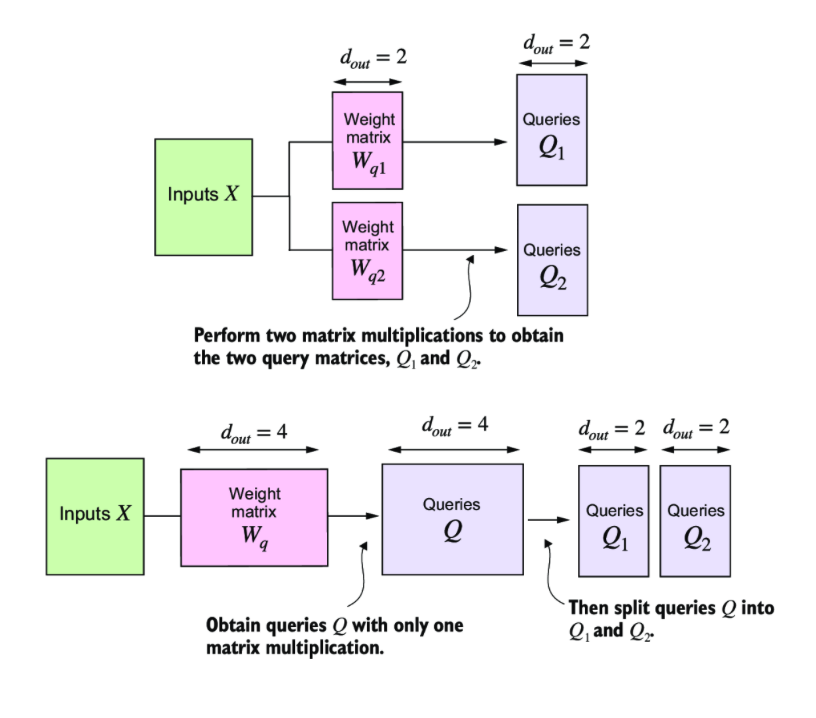

In [37]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, 
                 context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert (d_out % num_heads == 0), \
            "d_out must be divisible by num_heads"

        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads    #Reduces the projection dim to match the desired output dim
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out)    # Uses a Linear layer to combine head outputs
        self.dropout = nn.Dropout(dropout)
        self.register_buffer(
            "mask",
            torch.triu(torch.ones(context_length, context_length),
                       diagonal=1)
        )

    def forward(self, x):
        b, num_tokens, d_in = x.shape
        keys = self.W_key(x)         #  Tensor shape: (batch, num_tokens, d_out)
        queries = self.W_query(x)    #3
        values = self.W_value(x)     #3

        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim) # dimension of each head: (batch, num_tokens, num_heads, head_dim)
        values = values.view(b, num_tokens, self.num_heads, self.head_dim)  
        queries = queries.view(                                             
            b, num_tokens, self.num_heads, self.head_dim                    
        )                                                                   

        keys = keys.transpose(1, 2)          # Transposes from shape (b, num_tokens, num_heads, head_dim) to (b, num_heads, num_tokens, head_dim)
        queries = queries.transpose(1, 2)    #5
        values = values.transpose(1, 2)      #5

        attn_scores = queries @ keys.transpose(2, 3)   # Computes dot product for each head
        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]    # Using mask to fill attention scores

        attn_scores.masked_fill_(mask_bool, -torch.inf)     

        attn_weights = torch.softmax(
            attn_scores / keys.shape[-1]**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)

        context_vec = (attn_weights @ values).transpose(1, 2)   # Tensor shape: (b, num_tokens, n_heads, head_dim)
        context_vec = context_vec.contiguous().view(  # Combines heads, where self.d_out = self.num_heads * self.head_dim
            b, num_tokens, self.d_out
        )
        context_vec = self.out_proj(context_vec)    # Optional linear projection of contect vectors
        return context_vec 

In [41]:
torch.manual_seed(123)
batch_size, context_length, d_in = batch.shape
d_out = 4
mha = MultiHeadAttention(d_in, d_out, context_length, 0.0, num_heads=2)
context_vecs = mha(batch)
print(context_vecs)
print("context_vecs.shape:", context_vecs.shape)  

tensor([[[ 0.1184,  0.3120, -0.0847, -0.5774],
         [ 0.0178,  0.3221, -0.0763, -0.4225],
         [-0.0147,  0.3259, -0.0734, -0.3721],
         [-0.0116,  0.3138, -0.0708, -0.3624],
         [-0.0117,  0.2973, -0.0698, -0.3543],
         [-0.0132,  0.2990, -0.0689, -0.3490]],

        [[ 0.1184,  0.3120, -0.0847, -0.5774],
         [ 0.0178,  0.3221, -0.0763, -0.4225],
         [-0.0147,  0.3259, -0.0734, -0.3721],
         [-0.0116,  0.3138, -0.0708, -0.3624],
         [-0.0117,  0.2973, -0.0698, -0.3543],
         [-0.0132,  0.2990, -0.0689, -0.3490]]], grad_fn=<ViewBackward0>)
context_vecs.shape: torch.Size([2, 6, 4])
